In [48]:
import torch
from torch.optim import SGD
from torch.optim.lr_scheduler import StepLR

In [79]:
from torch.optim.lr_scheduler import MultiStepLR, ExponentialLR


def loss_fn(w):
    return 0.05*w[0]**2 + w[1]**2

def grad_lr(w,epochs,optimizer,scheduler):
    w1_history = []
    w2_history = []
    lr_history = []
    for epoch in range(epochs):
         loss=loss_fn(w)
         w1_history.append(w[0].item())
         w2_history.append(w[1].item())

         lr_history.append(optimizer.param_groups[0]['lr'])
         loss.backward()
         optimizer.step()
         optimizer.zero_grad()
         scheduler.step()
         # print("loss:",loss.item(),"lr:",optimizer.param_groups[0]['lr'])
    return w1_history,w2_history,lr_history
w=[-7.0,2]
tensor_w=torch.tensor(w,requires_grad=True)
optimizer=SGD([tensor_w],lr=1)

# lr(t) = lr_0 × gamma^t
lr_scheduler = ExponentialLR(optimizer, gamma=0.9)
# lr_scheduler = MultiStepLR(optimizer, milestones=[10, 20, 50], gamma=0.5)
# lr_scheduler=StepLR(optimizer,step_size=10,gamma=0.5)
w1_history,w2_history,lr_history=grad_lr(tensor_w,100,optimizer,lr_scheduler)

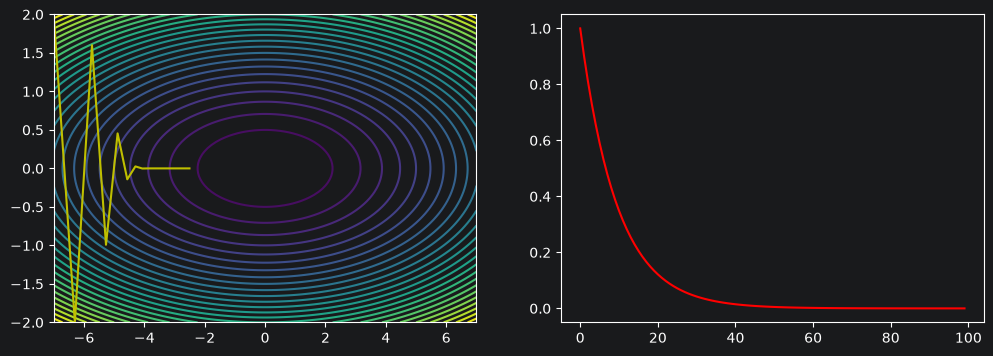

In [80]:
import numpy as np
from matplotlib import pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

w1=np.linspace(-7,7,100)
w2=np.linspace(-2,2,100)
W= np.meshgrid(w1,w2)
Z= loss_fn(W)
ax[0].contour(W[0],W[1],Z,levels=30)
ax[0].plot(w1_history,w2_history,color='y',label='loss')
ax[1].plot(lr_history,color='red',label='lr')
# ax[1].legend()
plt.show()